TP3 - Jann Luna Pedro - Pandas - 25/11/2025

Dans ce troisième TP, nous allons travailler avec certaines fonctions d'organisation des données et des tableaux à l'aide de la bibliothèque Pandas.

In [10]:
import numpy
import pandas
import matplotlib.pyplot

In [11]:
#1

#Calcul du nombre  de voix obtenues par le candidat "MÉLENCHON Jean-Luc"

data_presidentielles = pandas.read_csv("elections-presidentielles-2017-1ertour.csv",  sep =';')
# print(data_presidentielles)

df_1 = pandas.DataFrame(data_presidentielles)
voix_m = df_1['MÉLENCHON Jean-Luc']

total_voix = numpy.sum(voix_m)

print(total_voix)
print(f'le nombre total de votes était de {total_voix} (MÉLENCHON Jean-Luc)')

210548
le nombre total de votes était de 210548 (MÉLENCHON Jean-Luc)


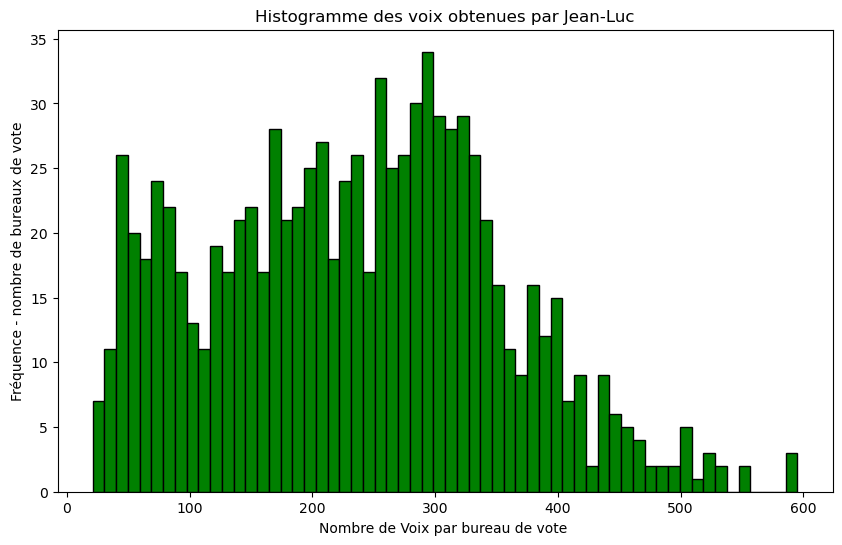

In [12]:
#2

# l'histogramme pour visualiser la répartition des voix de Méchelon.

y = voix_m
fig = matplotlib.pyplot.figure(figsize=(10, 6))

#en utilisant la fonction apprise dans TP2:
matplotlib.pyplot.hist(y, bins=60, color='g', edgecolor = 'black')
matplotlib.pyplot.title("Histogramme des voix obtenues par Jean-Luc") 
matplotlib.pyplot.xlabel('Nombre de Voix par bureau de vote ')
matplotlib.pyplot.ylabel('Fréquence - nombre de bureaux de vote')

#show histo
matplotlib.pyplot.show()

In [13]:
#3

#On va regrouper les données par arrondissement
#pour compter le nombre de bureaux de vote dans chacun.

groupes_compter = df_1.groupby('NUM_ARROND')['ID_BVOTE']

print(groupes_compter)

#comptage
bureaux_par_arr = groupes_compter.count()

print(bureaux_par_arr)
print("Le résultat montre le total des bureaux de vote par arrondissement.")

NUM_ARROND
1     10
2     10
3     15
4     14
5     25
6     22
7     25
8     18
9     27
10    39
11    55
12    64
13    71
14    57
15    95
16    68
17    67
18    68
19    70
20    76
Name: ID_BVOTE, dtype: int64
Le résultat montre le total des bureaux de vote par arrondissement.


In [14]:
#4

#Extraction des voix obtenues par Hamon pour bureau de vote.

#colonnes ID_BVOTE et HAMON Benoît
voix_ha = df_1[['ID_BVOTE', 'HAMON Benoît']]

print(voix_ha.head())

print('Les données pour nombre de voix obtenues par Hamon dans bureau de vote')

  ID_BVOTE  HAMON Benoît
0    15-49           107
1    15-51           126
2    15-77            90
3    16-42            29
4    16-55            27
Les données pour nombre de voix obtenues par Hamon dans bureau de vote


In [15]:
#5

#diviser le df par arrondissement
grupes_arr = df_1.groupby('NUM_ARROND')

#somme (nouveau df)
resultats_par_arr = grupes_arr.sum()

# print(type(resultats_par_arr))

# affichage
# print(resultats_par_arr)
print("Le tableau montre le total des voix obtenues par candidat dans chaque arrondissement.")

# columns candidats
columns_candidats = df_1.columns[16:27]

print(resultats_par_arr[columns_candidats])

Le tableau montre le total des voix obtenues par candidat dans chaque arrondissement.
            DUPONT-AIGNAN Nicolas  LE PEN Marine  MACRON Emmanuel  \
NUM_ARROND                                                          
1                             128            443             3561   
2                             128            399             5013   
3                             183            615             8325   
4                             214            735             6182   
5                             459           1225            12316   
6                             268            719             8729   
7                             324           1064             8785   
8                             241            916             6568   
9                             390           1092            14029   
10                            577           1817            16880   
11                           1067           3035            29191   
12               

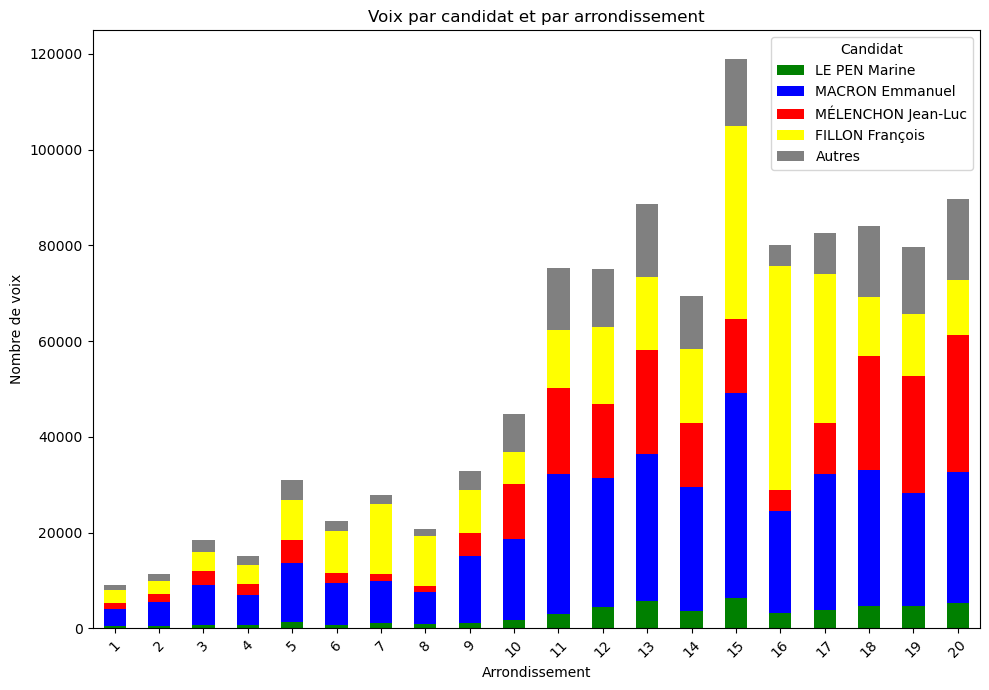

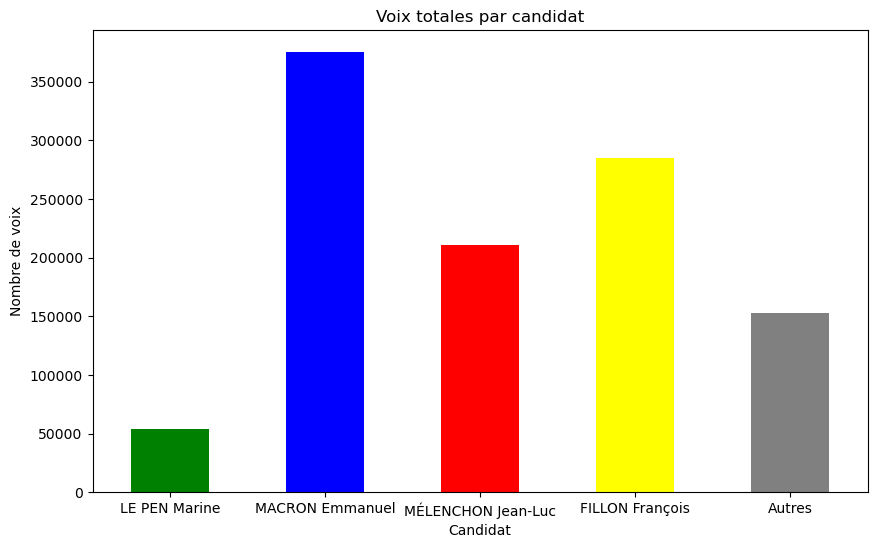

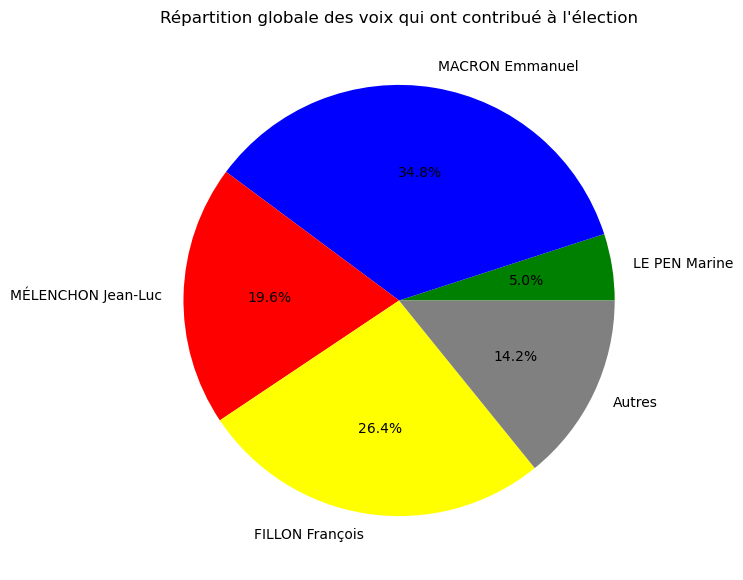

In [16]:
#6

#on va visualiser la répartition des voix

# Les résultats des quatre candidats principaux et de la catégorie 'Autres' sont montrés
# par diagrammes en barres et un camembert.

#candidats et couleurs
candidats = ['LE PEN Marine', 'MACRON Emmanuel', 'MÉLENCHON Jean-Luc', 'FILLON François']
colors = ['green', 'blue', 'red', 'yellow', 'gray'] 

#autres
tous_candidats_cols = df_1.columns[16:27].tolist() 

# diviser, sélectionner et sommer (data)
# Calcul des totaux pour le Top 4 et les Autres

df_par_candidat = df_1[tous_candidats_cols].sum()
sum_top4 = df_par_candidat[candidats].sum()
sum_tous = df_par_candidat.sum()
sum_autres = sum_tous - sum_top4
series_autres = pandas.Series([sum_autres], index=['Autres'])
globale = pandas.concat([df_par_candidat[candidats], series_autres])

#data par arrondissement
df_par_arr = df_1.groupby('NUM_ARROND')[tous_candidats_cols].sum()
df_total_tous_arr = df_par_arr.sum(axis=1) 
df_total_top4_arr = df_par_arr[candidats].sum(axis=1)
df_autres_arr = df_total_tous_arr - df_total_top4_arr
df_comparaison_avec_autres = df_par_arr[candidats].copy()
df_comparaison_avec_autres['Autres'] = df_autres_arr

#par arrondissement barres
matplotlib.pyplot.figure(figsize=(10, 7))
axe_arr = matplotlib.pyplot.gca() 
df_comparaison_avec_autres.plot(kind='bar', stacked=True, color=colors, ax=axe_arr)
axe_arr.set_title("Voix par candidat et par arrondissement")
axe_arr.set_ylabel("Nombre de voix")
axe_arr.set_xlabel("Arrondissement")
axe_arr.legend(title='Candidat')
matplotlib.pyplot.xticks(rotation=45) 
matplotlib.pyplot.tight_layout()
matplotlib.pyplot.show()

#répresentation en barres
matplotlib.pyplot.figure(figsize=(10, 6))
axe_barres = matplotlib.pyplot.gca() 
globale.plot(kind='bar', color=colors, ax=axe_barres)#barres
axe_barres.set_title("Voix totales par candidat")
axe_barres.set_ylabel("Nombre de voix")
axe_barres.set_xlabel("Candidat")
matplotlib.pyplot.xticks(rotation=0) 
matplotlib.pyplot.show()

#répresentation en camembert 
matplotlib.pyplot.figure(figsize=(7, 7))
axe_camembert = matplotlib.pyplot.gca() 
globale.plot(kind='pie', autopct='%1.1f%%', colors=colors, ax=axe_camembert)#camembert 
axe_camembert.set_title("Répartition globale des voix qui ont contribué à l'élection")
axe_camembert.set_ylabel("") 
matplotlib.pyplot.show()



Réponse 6:

Le diagramme en barres est la meilleure représentation pour cette comparaison.

Il permet de comparer directement le nombre absolu de voix obtenues par chaque candidat. Le camembert, bien que montrant les proportions, est moins efficace pour voir des différences de taille entre les parts qui sont proches.

Je pense que la représentation de tous les arrondissements dans le même graphique camembert serait étrange, j'ai donc fait la comparaison entre tous les votes exprimés (dans le camembert).

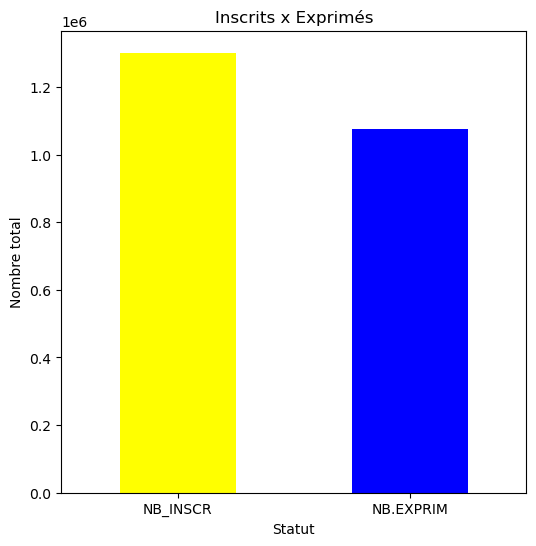

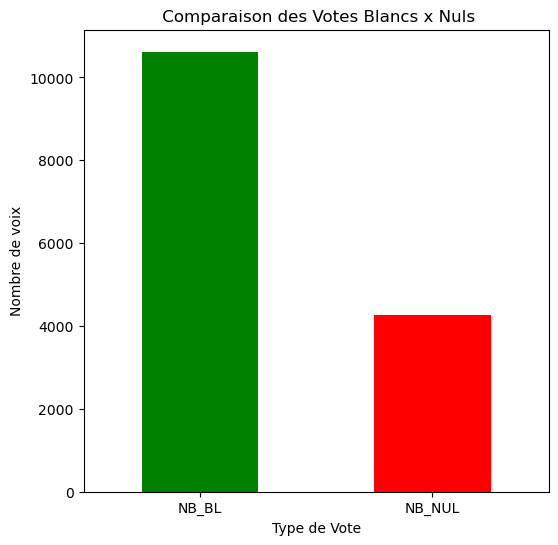

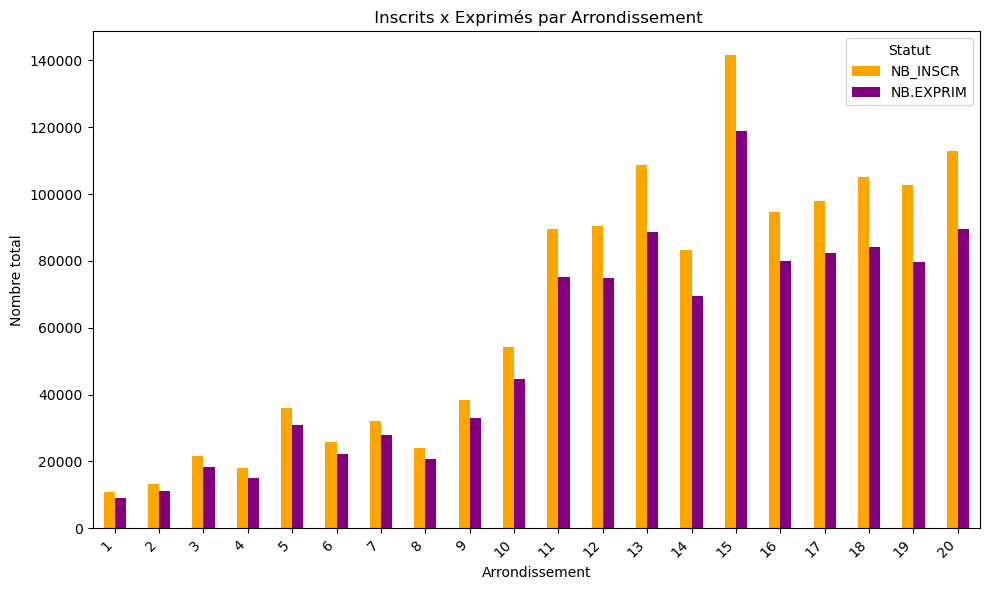

In [17]:
#7

#L'idée est d'analyser la proportion d'inscrits qui ont voté pour des
#candidats, et où sont allés les votes de ceux qui n'ont pas voté.

#inscrits et exprimés
global_situ = df_1[['NB_INSCR', 'NB.EXPRIM']].sum()

matplotlib.pyplot.figure(figsize=(6, 6))
axe_1 = matplotlib.pyplot.gca()
global_situ.plot(kind='bar', color=['yellow', 'blue'], ax=axe_1)
axe_1.set_title("Inscrits x Exprimés")
axe_1.set_ylabel("Nombre total")
axe_1.set_xlabel("Statut")
matplotlib.pyplot.xticks(rotation=0)
matplotlib.pyplot.show()


#comparaison des votes perdus 

wasted_votes = df_1[['NB_BL', 'NB_NUL']].sum()
matplotlib.pyplot.figure(figsize=(6, 6))
axe_2 = matplotlib.pyplot.gca()
wasted_votes.plot(kind='bar', color=['green','red'], ax=axe_2)
axe_2.set_title(" Comparaison des Votes Blancs x Nuls")
axe_2.set_ylabel("Nombre de voix")
axe_2.set_xlabel("Type de Vote")
matplotlib.pyplot.xticks(rotation=0)
matplotlib.pyplot.show()


#inscrits et exprimés par arrondissement
df_inscrits_exprim = df_1.groupby('NUM_ARROND')[['NB_INSCR', 'NB.EXPRIM']].sum()

matplotlib.pyplot.figure(figsize=(10, 6))
axe_2 = matplotlib.pyplot.gca()
df_inscrits_exprim.plot(kind='bar', ax=axe_2, color=['orange', 'purple'])
axe_2.set_title(" Inscrits x Exprimés par Arrondissement")
axe_2.set_ylabel("Nombre total")
axe_2.set_xlabel("Arrondissement")
axe_2.legend(title='Statut')
matplotlib.pyplot.xticks(rotation=45, ha='right')
matplotlib.pyplot.tight_layout()
matplotlib.pyplot.show()




7

J'ai choisi de montrer un peu la relation entre les inscrits et les exprimés, en plus de montrer comment les votes blancs et nuls se sont répartis. Je pense que c'est important car cela montre la part de la population qui n'est pas satisfaite des options proposées ou qui n'a pas envie de manifester son intérêt pour un candidat en particulier.

Les graphiques ont permis d'observer que :

1. Parmi les inscrits, la majorité a voté pour un candidat.

2. Parmi les votes blancs et nuls, les votes blancs ont été pratiquement deux fois plus nombreux que les votes nuls.

3. La proportion des votes en faveur des candidats par rapport au nombre total d'inscrits est similaire dans chaque arrondissement.